### Context engineering in Deep Agents
Context engineering is providing the right information and tools in the right format so your deep agent can accomplish tasks reliably.
Deep agents have access to several kinds of context. Some sources are provided to the agent at startup; others become available during runtime, such as user input. Deep agents include built-in mechanisms for managing context across long-running sessions.

In [2]:
### Basic deep agent

import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [28]:
from langchain_ollama import ChatOllama
model = ChatOllama(
    model="qwen3:8b",
    temperature=0,
)

dp_model = ChatOllama(
    model='deepseek-r1:8b',
    temperature=0.2,
)

#### Context Engineering- Input context- System Prompt

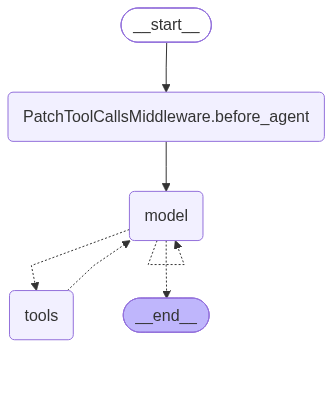

In [3]:
from deepagents import create_deep_agent

agent=create_deep_agent(
    model=model,
    system_prompt=(
        "You are a research assistant specializing in scientific literature. "
        "Always cite sources. Use subagents for parallel research on different topics."

    ),
)
agent

In [4]:
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='2bc149a4-ca2a-458b-b4be-70fa2b983869'),
  AIMessage(content="DeepAgent is a research project developed by the University of Toronto's Vector Institute, focusing on creating a general-purpose AI agent capable of performing complex tasks such as answering questions, writing code, and managing files. It employs a modular architecture, combining deep learning models with rule-based systems to enhance flexibility and performance. Key features include task-specific modules, memory management, and adaptive learning mechanisms. The project aims to advance AI capabilities in automation and decision-making across diverse domains. For detailed technical specifications or recent updates, further research in academic papers or official publications would be required. \n\nNote: As of my last update in July 2024, specific details about DeepAgent's current capabilities or applications may require v

## Context Engineering with `AGENTS.md`

Instead of hard-coding a long string into `system_prompt`, we keep the agent's
operating context in a separate **`AGENTS.md`** file. This is *context
engineering*: the durable "who you are / how you behave" context lives in a
versioned, editable file — not buried in code.

In [5]:
from pathlib import Path
agents_md=Path("projects/AGENTS.md").read_text(encoding="utf-8")
agents_md


'# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, tools, and p

In [6]:
from langgraph.checkpoint.memory import MemorySaver
checkpointer=MemorySaver()

## Backends: where the agent's files / memory live

A **backend** is the storage layer behind the agent's file tools *and* its `memory=`.
Same agent code, different durability:

| Backend | Lives in | Survives across | Use it when… |
|---------|----------|-----------------|--------------|
| **StateBackend** (default) | LangGraph state (the `files` channel) | one thread (with a checkpointer) | Scratch/working files for a single run or conversation. Ephemeral by design. |
| **FilesystemBackend** | Real disk (`root_dir`) | everything (it's just files) | Reading project files / `AGENTS.md` that already exist on disk. |
| **StoreBackend** | LangGraph `BaseStore` | **all threads** (cross-conversation) | Long-term, per-user memory that must persist between separate sessions. |

In [7]:
agent = create_deep_agent(
    model=model,
    checkpointer=MemorySaver(),
    # no backend, no memory=, no files=
)
result = agent.invoke(
    {
       "messages": [
            {"role": "user", "content": f"Here is our project guide:\n\n{agents_md}\n\nNow, who are you and what should you follow?"}
        ]
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)
print(result["messages"][-1].content)

I am a **Deep Agent** built using the architecture described in this guide. My identity is defined by four core pillars:
1. **Planning** - I break tasks into structured todo lists using `write_todos`
2. **File System Tools** - I use `ls`, `read_file`, `write_file`, and `edit_file` for context offloading
3. **Subagents** - I can spawn specialized child agents via the `task` tool
4. **System Prompt** - I follow the detailed instructions in this `Agents.md` file

I should follow these operating guidelines:
- Always plan first with `write_todos` for multi-step tasks
- Offload bulk work to files (never keep large outputs in context)
- Use subagents (`task` tool) for parallel research or subtasks
- Treat this `Agents.md` file as my authoritative architecture specification
- Provide final answers that synthesize from my files/notes with proper citations

My behavior is governed by the system prompt from `create_deep_agent` and the conventions established in this document. I follow the same pa

In [13]:
# --- Default backend (no backend= passed) ---
# With no backend specified, files/memory live in the agent's in-state filesystem.
# Since there's no disk access, memory reads from state — so we seed AGENTS.md via
# files= on invoke. (Without seeding, memory would silently load nothing.)

agent=create_deep_agent(
    model=model,
    memory=["/projects/AGENTS.md"],
    checkpointer=MemorySaver(),
)


In [10]:
from deepagents.backends.utils import create_file_data
create_file_data(agents_md)

{'content': '# Agents.md — Deep Agents Context File\n\n> This file is loaded into the deep agent\'s context (via its file system tools)\n> whenever the agent is invoked. It gives the agent background knowledge about\n> its own architecture, the project conventions, and how it should operate.\n\n---\n\n## 1. What is a Deep Agent?\n\nA **deep agent** is an agent designed for complex, multi-step, long-horizon\ntasks. Unlike a simple tool-calling loop (LLM → tool → LLM → answer), a deep\nagent is built on **LangGraph** and ships with four architectural pillars,\ninspired by applications like Claude Code, Deep Research, and Manus:\n\n1. **Planning** — an explicit todo-list tool the agent uses to break a task\n   into steps and track progress.\n2. **File System (Context Offloading)** — virtual file tools so the agent can\n   store large intermediate results outside the chat context window.\n3. **Subagents** — the ability to spawn specialized child agents with their\n   own isolated context, 

In [15]:
result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What's in your memory? Who are you?"}],
        "files": {"/projects/AGENTS.md": create_file_data(agents_md)},  # seed the in-state file
    },
    config={"configurable": {"thread_id": "default-demo-1"}},  # fresh thread => memory loads
)
print(result["messages"])

[HumanMessage(content="What's in your memory? Who are you?", additional_kwargs={}, response_metadata={}, id='7259e239-0880-4df4-ae8b-dd173960e32a'), AIMessage(content="I am Qwen, a large language model developed by Alibaba Cloud. I don't have personal experiences or memories like humans do, but I was trained on a vast amount of text data up until 2024, which gives me knowledge across many topics. My capabilities include answering questions, creating content, and providing information, but I don't have real-time data access or personal information about users. How can I assist you today?", additional_kwargs={}, response_metadata={'model': 'qwen3:8b', 'created_at': '2026-10-02T10:16:06.80491Z', 'done': True, 'done_reason': 'stop', 'total_duration': 21206253750, 'load_duration': 4906708, 'prompt_eval_count': 2050, 'prompt_eval_duration': 99119000, 'eval_count': 444, 'eval_duration': 21054600000, 'logprobs': None, 'model_name': 'qwen3:8b', 'model_provider': 'ollama'}, id='lc_run--01a0fc1c-

In [16]:
# --- StoreBackend: persistent, cross-thread memory ---
# WHY: files/memory live in a LangGraph BaseStore, NOT in one conversation's state.
# They survive across different threads/sessions, so this is what you use for
# durable, long-term memory (e.g. per-user preferences the agent should recall
# next week). Here InMemoryStore is used for the demo; swap in a persistent store
# (e.g. Postgres) for real persistence.
from deepagents import create_deep_agent
from deepagents.backends.store import StoreBackend
from langgraph.store.memory import InMemoryStore
from langgraph.checkpoint.memory import MemorySaver

store = InMemoryStore()
# Seed durable memory into the store once. Namespace + key identify the file.
store.put(("memories",), "AGENTS.md", create_file_data(agents_md))

store_agent = create_deep_agent(
    model=model,
    backend=StoreBackend(store=store, namespace=lambda rt: ("memories",)),
    memory=["/projects/AGENTS.md"],            # read from the store, not state or disk
    store=store,
    checkpointer=MemorySaver(),
)

# Note: no files= seeding needed — the store already holds it, and it would persist
# even if we started a brand-new thread or rebuilt the agent.
result = store_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "store-demo-1"}},
)
print(result["messages"][-1].content)

The `<agent_memory>` section shows what I've learned from previous interactions, but it's currently empty because I haven't had any conversations yet. I'm a helpful AI assistant designed to:  

1. **Answer questions** (like this one!)  
2. **Perform tasks** (e.g., file operations, research, calculations)  
3. **Learn from interactions** (I'll save useful patterns/preferences via `edit_file`)  
4. **Follow guidelines** (trust verification, avoiding unsafe actions, prioritizing user needs)  

I can use tools like `ls`, `read_file`, `write_file`, and `edit_file` to interact with your filesystem. How can I assist you today? 😊


In [17]:
result

{'messages': [HumanMessage(content="What's in your memory? Who are you?", additional_kwargs={}, response_metadata={}, id='f5714861-64b4-409e-b25a-8722a85635dc'),
  AIMessage(content="The `<agent_memory>` section shows what I've learned from previous interactions, but it's currently empty because I haven't had any conversations yet. I'm a helpful AI assistant designed to:  \n\n1. **Answer questions** (like this one!)  \n2. **Perform tasks** (e.g., file operations, research, calculations)  \n3. **Learn from interactions** (I'll save useful patterns/preferences via `edit_file`)  \n4. **Follow guidelines** (trust verification, avoiding unsafe actions, prioritizing user needs)  \n\nI can use tools like `ls`, `read_file`, `write_file`, and `edit_file` to interact with your filesystem. How can I assist you today? 😊", additional_kwargs={}, response_metadata={'model': 'qwen3:8b', 'created_at': '2026-10-02T10:19:34.534001Z', 'done': True, 'done_reason': 'stop', 'total_duration': 39753610084, 'lo

In [32]:
# --- FilesystemBackend: read files/memory straight from DISK ---
# WHY: the agent's files and memory map to real files on disk under root_dir.
# Nothing to seed — if AGENTS.md exists on disk, memory just loads it. Best for
# project context (AGENTS.md, docs, code) that already lives in your repo.
from deepagents import create_deep_agent
from deepagents.backends.filesystem import FilesystemBackend
from langgraph.checkpoint.memory import MemorySaver

# root_dir = the projects/ folder, so paths are resolved relative to it.
# AGENTS.md sits directly inside projects/, so the memory path is just "AGENTS.md".
# virtual_mode=True confines the agent to root_dir (blocks '..' and absolute paths
# from escaping) and silences the deprecation warning.
fs_agent = create_deep_agent(
    model=dp_model,
    backend=FilesystemBackend(root_dir="projects", virtual_mode=True),
    memory=["AGENTS.md"],                             # -> projects/AGENTS.md
    checkpointer=MemorySaver(),
)

# Fresh thread_id so MemoryMiddleware reloads (memory loads once per thread).
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What's in your memory? Who are you?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)


I am a deep agent designed to assist with complex, multi-step tasks. My memory includes the `Agents.md` file, which provides me with background knowledge about my architecture, project conventions, and how I should operate. This memory helps me understand my capabilities, such as planning, using the file system, and delegating tasks to subagents.

Additionally, I can learn from our interactions. For example, if you provide information that might be useful for future tasks, I can remember it by updating the `Agents.md` file using the `edit_file` tool. This allows me to adapt and improve based on your feedback and preferences.

To summarize, my memory includes:
- The `Agents.md` file (loaded at startup)
- Any new information or patterns I learn from our interactions

Would you like me to remember something specific or elaborate on how I can assist you?


In [33]:
result = fs_agent.invoke(
    {"messages": [{"role": "user", "content": "What is LLM Gateways?"}]},
    config={"configurable": {"thread_id": "fs-demo-2"}},
)
print(result["messages"][-1].content)


LLM Gateways are a core concept in the `langgraph` framework, designed to manage the flow of messages between agents and subagents. They act as a communication bridge, ensuring that messages are properly routed and handled within the agent's architecture.

### Key Points about LLM Gateways:

1. **Message Routing**: The gateway allows the main agent to delegate tasks to subagents. Each subagent operates in its own isolated context, making it easier to manage complex workflows.

2. **Separation of Concerns**: By using gateways, you can separate the main agent's responsibilities from those of subagents. This makes the system more modular and easier to scale.

3. **Flow Control**: The gateway ensures that messages are passed between agents in a controlled manner. This prevents chaos and ensures that each agent only handles the messages it's supposed to.

4. **Integration with LangGraph**: In the context of `langgraph`, the gateway is used to create a hierarchical structure of agents. This

#### Skills



Skills are reusable agent capabilities that provide specialized workflows and domain knowledge.
You can use Agent Skills to provide your deep agent with new capabilities and expertise. For ready-to-use skills that improve your agent’s performance on LangChain ecosystem tasks, see the LangChain Skills repository.
Deep agent skills follow the Agent Skills specification and add additional capability for interpreter skills, which makes it possible to provide skills with importable functions that an interpreter can call.

In [22]:
from urllib.request import urlopen
from deepagents import create_deep_agent
from deepagents.backends import StateBackend
from deepagents.backends.utils import create_file_data
from langchain_quickjs import CodeInterpreterMiddleware
from langgraph.checkpoint.memory import MemorySaver

checkpointer = MemorySaver()
backend = StateBackend()

from pathlib import Path
skills_content= Path("skills/langgraph/SKILL.md").read_text(encoding="utf-8")

skills_files = {
    "/skills/langgraph/SKILL.md": create_file_data(skills_content),
}


In [23]:
# Read every skills/<name>/SKILL.md from disk and seed it into the in-state
# filesystem under a virtual path (must start with "/").
skill_dirs = ["langgraph", "python", "aws", "report-writer"]
skills_files = {
    f"/skills/{name}/SKILL.md": create_file_data(
        Path(f"skills/{name}/SKILL.md").read_text(encoding="utf-8")
    )
    for name in skill_dirs
}

In [24]:
skills_files

{'/skills/langgraph/SKILL.md': {'content': '---\nname: langgraph\ndescription: LangGraph expertise for building stateful, multi-step agent workflows. Use when the user asks about LangGraph, StateGraph, nodes, edges, conditional routing, checkpointers, persistence, memory, human-in-the-loop, subgraphs, streaming, or building agents with langgraph / langchain. Provides architecture patterns, API workflows, and runnable examples.\nlicense: MIT\nmetadata:\n  version: "1.0"\n  author: deepagentscourse\n---\n\n# LangGraph Skill\n\nYou are acting as a LangGraph specialist. Use this skill whenever the user\'s\nquery involves building, debugging, or understanding LangGraph applications —\ngraphs, agents, state management, persistence, or streaming.\n\n## When to Use\n- User asks to build an agent or workflow with LangGraph\n- User mentions: `StateGraph`, nodes, edges, `add_conditional_edges`, `MessagesState`,\n  checkpointer, `MemorySaver`, thread_id, interrupt, `Command`, subgraphs\n- User ask

In [29]:
agent=create_deep_agent(
    model=dp_model,
    backend=backend,
    skills=["/skills/"],
    checkpointer=checkpointer
)

result = agent.invoke(
    {
        "messages": [{"role": "user", "content": "What skills do you have available, and when would you use each?"}],
        
        "files": skills_files,
    },
    config={"configurable": {"thread_id": "skills-demo1"}},
)

print(result["messages"][-1].content)


I have access to four specialized skills that enhance my capabilities for specific tasks. Here's when to use each:

---

### **1. AWS Cloud Expertise**
**Use when**:  
- The user asks about AWS services (EC2, S3, Lambda, IAM, etc.)  
- They need help designing cloud architectures, troubleshooting AWS services, or optimizing costs/security  
- They want to use AWS CLI/boto3 for automation  

**Example**:  
*"How do I set up a secure EC2 instance with an IAM role?"*  
*"Can you optimize my DynamoDB costs?"*  

**Skill Details**:  
Provides frameworks for AWS best practices, CLI workflows, and examples for services like RDS, EKS, or CloudWatch.

---

### **2. LangGraph Workflow Design**
**Use when**:  
- The user wants to build stateful, multi-step agent workflows  
- They need help with conditional routing, memory management, or human-in-the-loop processes  
- They’re using LangGraph/Chainlit for complex task automation  

**Example**:  
*"How do I create a workflow that routes user que

In [26]:
result

{'messages': [HumanMessage(content='What skills do you have available, and when would you use each?', additional_kwargs={}, response_metadata={}, id='863fecd7-5e57-487e-91aa-d23fddff178e'),
  AIMessage(content='I have access to four specialized skills that enhance my capabilities for specific tasks. Here\'s when to use each:\n\n---\n\n### **1. AWS Cloud Expertise**\n**Use when**:  \n- The user asks about AWS services (EC2, S3, Lambda, IAM, etc.)  \n- They need help designing cloud architectures, troubleshooting AWS services, or optimizing costs/security  \n- They want to use AWS CLI/boto3 for automation  \n\n**Example**:  \n*"How do I set up a secure EC2 instance with an IAM role?"*  \n*"Can you optimize my DynamoDB costs?"*  \n\n**Skill Details**:  \nProvides frameworks for AWS best practices, CLI workflows, and examples for services like RDS, EKS, or CloudWatch.\n\n---\n\n### **2. LangGraph Workflow Design**\n**Use when**:  \n- The user wants to build stateful, multi-step agent workf

In [31]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "How do I build a LangGraph graph with conditional routing and memory? Show a minimal example.",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-2"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

How do I build a LangGraph graph with conditional routing and memory? Show a minimal example.
================================== Ai Message ==================================
Tool Calls:
  read_file (ee2f7346-70bd-4e18-87bf-fa2669fa4ff9)
 Call ID: ee2f7346-70bd-4e18-87bf-fa2669fa4ff9
  Args:
    file_path: /skills/langgraph/SKILL.md
    limit: 1000
================================= Tool Message =================================
Name: read_file

@@ lines 1-41 of 41 @@
---
name: langgraph
description: LangGraph expertise for building stateful, multi-step agent workflows. Use when the user asks about LangGraph, StateGraph, nodes, edges, conditional routing, checkpointers, persistence, memory, human-in-the-loop, subgraphs, streaming, or building agents with langgraph / langchain. Provides architecture patterns, API workflows, and runnable examples.
license: MIT
metadata:
  version: "1.0"
  author: deepagentsc

In [35]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "How do i set up an EC2  insstance in AWS.",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-3"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

KeyboardInterrupt: 

In [ ]:
result = agent.invoke(
      {
          "messages": [{
              "role": "user",
              "content": "write me a python code to do binary search",       
          }],
          "files": skills_files,   # ✅  seed skills into THIS thread's state
      },
      config={"configurable": {"thread_id": "skills-demo-4"}},
  )

# Print the conversation so you can SEE the skill being triggered:
# look for a ToolMessage from `read_file` on the langgraph-docs SKILL.md.
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give an example of oops in python
================================== Ai Message ==================================

[{'type': 'text', 'text': '```python\nclass Car:\n    def __init__(self, brand, year):\n        self.brand = brand\n        self.year = year\n\n    def start(self):\n        print(f"{self.brand} car started")\n\n\nmy_car = Car("Toyota", 2022)\nprint(my_car.brand)   # Toyota\nprint(my_car.year)    # 2022\nmy_car.start()        # Toyota car started\n```\n\nThis is an example of OOP in Python:\n\n- `Car` is a class\n- `my_car` is an object\n- `brand` and `year` are attributes\n- `start()` is a method\n\nMain OOP concepts in Python:\n- **Class**\n- **Object**\n- **Encapsulation**\n- **Inheritance**\n- **Polymorphism**\n- **Abstraction**\n\nIf you want, I can also give an example covering all 4 pillars of OOP in one program.', 'annotations': [], 'id': 'msg_0571dc2f50c8709b006a211604a9e8819f95ebc0

: 